In [1]:
import operator
from typing import Annotated, Sequence
from anthropic import BaseModel
from typing_extensions import TypedDict
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_core.runnables.config import RunnableConfig
from langgraph.graph import END, StateGraph, START
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()  # 必须要这句！
# 百炼模型（DashScope）
bailian_model = ChatOpenAI(
    model="qwen-plus",  # 或 qwen-max / qwen-turbo
    temperature=0,
    openai_api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
# OpenAI 模型
openai_model = ChatOpenAI(
    model="gpt-4o-mini",  # 推荐替换掉 3.5
    base_url="https://api.openai.com/v1/",
    openai_api_key=os.getenv("OPENAI_API_KEY"),
    temperature=0,
)
models= {
    "bailian": bailian_model,
    "openai": openai_model,
}
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], operator.add]
def _call_model(state: AgentState, config: RunnableConfig):
    # 使用LCEL的配置
    model_name = config["configurable"].get("model","openai")
    model = models[model_name]
    response = model.invoke(state["messages"])
    return {"messages": [response]}


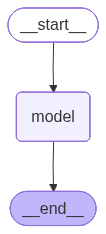

In [2]:
# Define a new graph
from IPython.display import Image,display
builder = StateGraph(AgentState)
builder.add_node("model", _call_model)
builder.add_edge(START, "model")
builder.add_edge("model", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [3]:
config = {"configurable": {"model": "openai"}} #账户没钱会报429的错误
graph.invoke({"messages": [HumanMessage(content="hi 你是谁?")]}, config=config)

RateLimitError: Error code: 429 - {'error': {'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, read the docs: https://platform.openai.com/docs/guides/error-codes/api-errors.', 'type': 'insufficient_quota', 'param': None, 'code': 'insufficient_quota'}}